**Descripción del Dataset**

El conjunto de datos utilizado corresponde al Predict Students' Dropout and Academic Success Data Set (ID UCI 697, alojado en el repositorio público de Machine Learning de la Universidad de California en Irvine - UCI, obtenido mediante la librería ucimlrepo).   
**Contexto**: Registra atributos sociodemográficos, socioeconómicos y de
trayectoria académica pertenecientes a estudiantes matriculados en una institución de educación superior politécnica de Portugal.   
**Tamaño:** Consta de 4424 registros y 38 variables (36 predictoras originales y 1 target multiclase en la fuente original). El análisis se acota a una selección estratégica de 9 atributos predictores representativos del perfil del alumno y su rendimiento inicial.   

**Formulación del Problema y Pregunta de Investigación**

**Problema:** En el ámbito de la gestión y permanencia universitaria, anticipar tempranamente qué estudiantes se encuentran en riesgo de deserción permite a la institución activar redes de tutoría, reasignación de becas y acompañamiento pedagógico antes de que el abandono se consolide.   
**Pregunta analítica:** ¿En qué medida las variables académicas del primer y segundo semestre (materias aprobadas y calificaciones), junto a factores socioeconómicos y demográficos clave (edad, género, becas, deudas de arancel y turno), permiten predecir de forma efectiva la probabilidad de deserción escolar frente a la continuidad de los estudios?   
**Objetivo:** Entrenar, evaluar y comparar modelos de clasificación supervisada (Árbol de Decisión y Máquinas de Vectores de Soporte - SVM con kernel RBF) para identificar oportunamente el riesgo de abandono escolar (Dropout), priorizando la sensibilidad métrica (Recall) y la interpretabilidad institucional.

**Identificación y Definición de Variables**

**Variables predictoras seleccionadas (X)**:

**Numéricas:**

**Age at enrollment:** Edad del estudiante al momento de la inscripción.         
**Curricular units 1st sem (approved)**: Cantidad de asignaturas aprobadas en el primer semestre.   
**Curricular units 1st sem (grade):** Promedio de calificaciones obtenido en el primer semestre.   
**Curricular units 2nd sem (approved):** Cantidad de asignaturas aprobadas en el segundo semestre.   
**Curricular units 2nd sem (grade):** Promedio de calificaciones obtenido en el segundo semestre.   

**Categóricas / Binarias:**

**Scholarship holder:** Condición de estudiante becado (1: Sí, 0: No).   
**Debtor:** Registro de deuda en cuotas o aranceles (1: Sí, 0: No).   
**Gender:** Género del estudiante (1: Masculino, 0: Femenino).   
**Daytime/evening attendance:** Régimen horario de cursada (1: Diurno, 0: Vespertino).   

**Variable objetivo / dependiente (y):** Target_binario — Condición de trayectoria académica redefinida de forma binaria:   
**1 (Dropout):** Alumno que abandonó sus estudios universitarios.   
**0 (No Dropout):** Alumno que continúa matriculado o que logró graduarse (Enrolled o Graduate).   

**Importacion de Librerías**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

In [3]:
!pip install ucimlrepo

**Carga y Revisión de Datos**

In [4]:
from ucimlrepo import fetch_ucirepo

# 1. Descarga directa oficial del dataset desde UCI (ID 697)
dataset_uci = fetch_ucirepo(id=697)

# 2. Unimos predictoras y target en un solo DataFrame
df = dataset_uci.data.features.copy()
df['Target'] = dataset_uci.data.targets.values.ravel()

# 3. Definición del target binario (1: Abandono / Dropout, 0: Graduado o Inscripto)
df['Target_binario'] = df['Target'].apply(lambda x: 1 if x == 'Dropout' else 0)

# 4. Verificación rápida
print("Dimensiones del dataset:", df.shape)
print("Distribución del target:")
print(df['Target_binario'].value_counts())
df.head(3)

Dimensiones del dataset: (4424, 38)
Distribución del target:
Target_binario
0    3003
1    1421
Name: count, dtype: int64


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Target_binario
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,0
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1


In [5]:
# Verificamos los nombres de las columnas que vamos a usar
num_cols = [
    'Age at enrollment',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)'
]

cat_cols = [
    'Scholarship holder',
    'Debtor',
    'Gender',
    'Daytime/evening attendance'
]

features = num_cols + cat_cols

# Filtramos la matriz de predictoras X y el vector objetivo y
X = df[features].copy()
y = df['Target_binario']

print("Predictoras seleccionadas:", X.shape[1])
X.head()

Predictoras seleccionadas: 9


,Age at enrollment,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Scholarship holder,Debtor,Gender,Daytime/evening attendance
0,20,0,0.000000,0,0.000000,0,0,1,1
1,19,6,14.000000,6,13.666667,0,0,1,1
2,19,0,0.000000,0,0.000000,0,0,1,1
3,20,6,13.428571,5,12.400000,0,0,0,1
4,45,5,12.333333,6,13.000000,0,0,0,0


**Partición de Datos y Escalado**

In [6]:
# 1. Partición de datos (75% train, 25% test) con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 2. Escalado de variables numéricas para modelos basados en distancias (SVM)
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Partición y escalado completados:")
print(f"- Conjunto de entrenamiento: {X_train.shape[0]} muestras")
print(f"- Conjunto de prueba: {X_test.shape[0]} muestras")

Partición y escalado completados:
- Conjunto de entrenamiento: 3318 muestras
- Conjunto de prueba: 1106 muestras


**Entrenamiento y Predicción de los Modelos**

In [7]:
# Modelo 1: Árbol de Decisión
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

# Modelo 2: SVM con Kernel RBF (con datos escalados)
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

print("Ambos modelos fueron entrenados y predijeron sobre el conjunto de test.")

Ambos modelos fueron entrenados y predijeron sobre el conjunto de test.


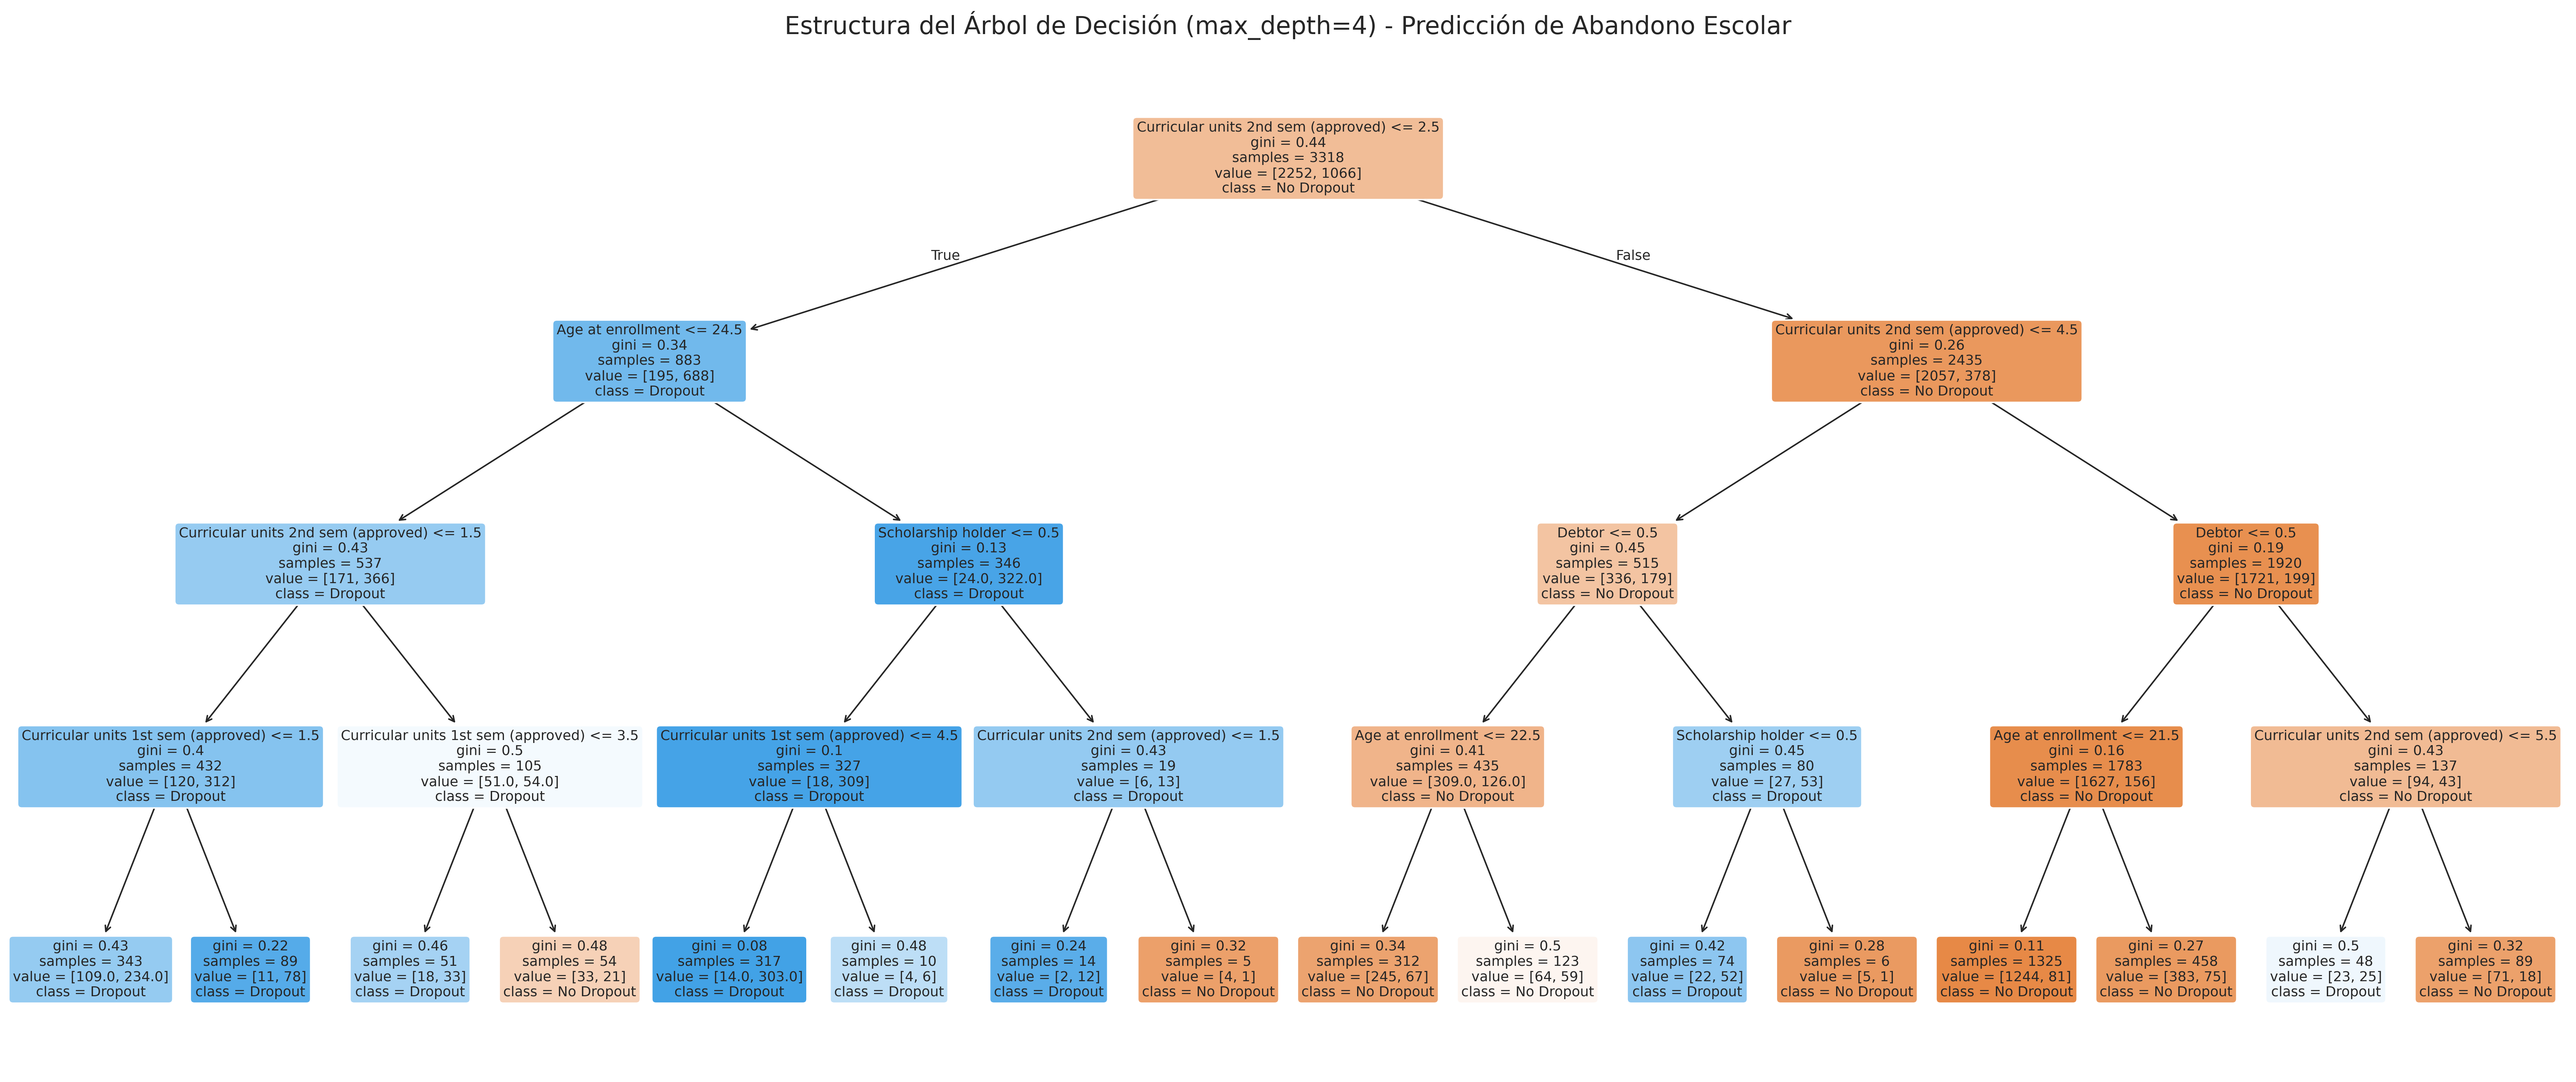

In [8]:
# Visualización del Árbol de Decisión
plt.figure(figsize=(24, 10), dpi=300)

plot_tree(
    tree_model,
    feature_names=features,
    class_names=['No Dropout', 'Dropout'],
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)

plt.title("Estructura del Árbol de Decisión (max_depth=4) - Predicción de Abandono Escolar", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

**Tabla Comparativa y Gráfico de Barras**

--- TABLA COMPARATIVA DE DESEMPEÑO ---


,Métrica,Árbol de Decisión,SVM (RBF)
0,Accuracy,0.854,0.847
1,Precision (Dropout),0.812,0.850
2,Recall (Dropout),0.707,0.637
3,F1-Score (Dropout),0.756,0.728


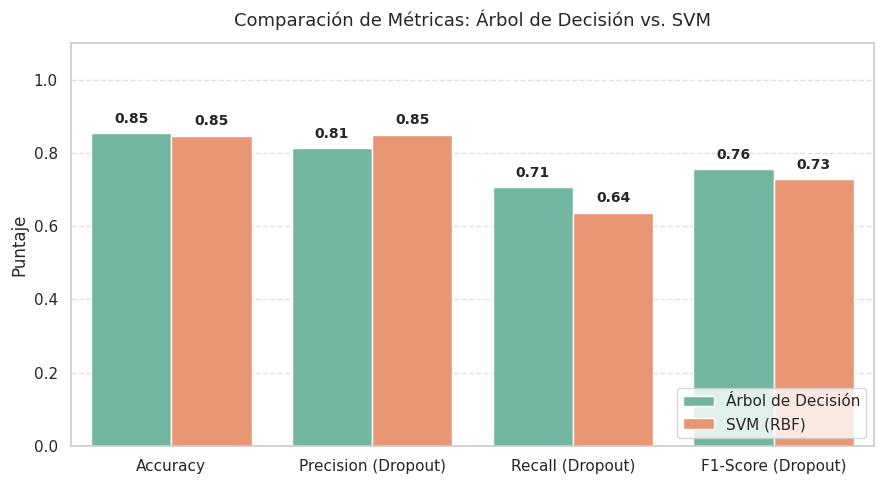

In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# 1. Cálculo de métricas principales para ambos modelos (enfocadas en la clase 1: Dropout)
metricas_data = {
    'Métrica': ['Accuracy', 'Precision (Dropout)', 'Recall (Dropout)', 'F1-Score (Dropout)'],
    'Árbol de Decisión': [
        accuracy_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_tree)
    ],
    'SVM (RBF)': [
        accuracy_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_svm)
    ]
}

df_comparativo = pd.DataFrame(metricas_data)

# Mostramos la tabla redondeada a 3 decimales
print("--- TABLA COMPARATIVA DE DESEMPEÑO ---")
display(df_comparativo.round(3))

# 2. Gráfico de barras comparativo
df_melted = df_comparativo.melt(id_vars='Métrica', var_name='Modelo', value_name='Valor')

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df_melted, x='Métrica', y='Valor', hue='Modelo', palette='Set2')

plt.title('Comparación de Métricas: Árbol de Decisión vs. SVM', fontsize=13, pad=12)
plt.ylim(0, 1.1)
plt.ylabel('Puntaje')
plt.xlabel('')
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Etiquetas con los valores sobre cada barra
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}",
                    (p.get_x() + p.get_width() / 2., h + 0.02),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Matrices de Confusión**

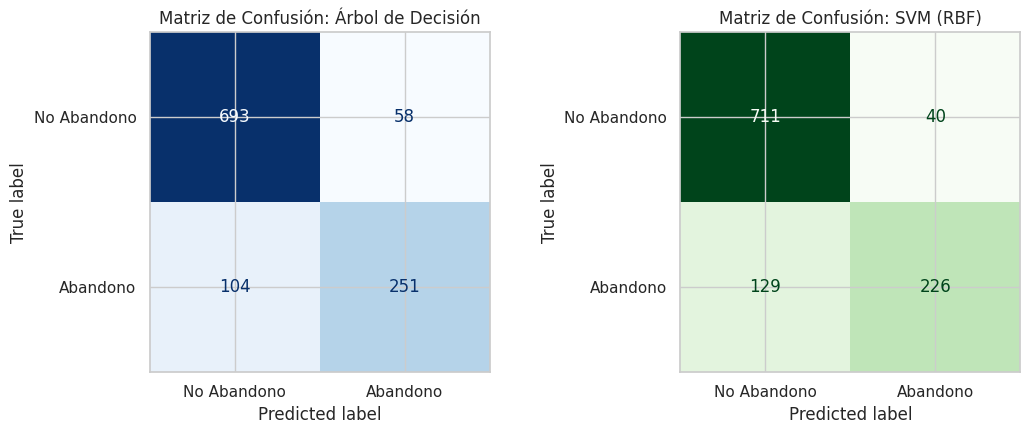

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tree,
    display_labels=['No Abandono', 'Abandono'],
    cmap='Blues',
    ax=axes[0],
    colorbar=False
)
axes[0].set_title('Matriz de Confusión: Árbol de Decisión')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm,
    display_labels=['No Abandono', 'Abandono'],
    cmap='Greens',
    ax=axes[1],
    colorbar=False
)
axes[1].set_title('Matriz de Confusión: SVM (RBF)')

plt.tight_layout()
plt.show()

**Conclusión y Justificación. Selección del Mejor Modelo**

**1. Comparación de Métricas y Matrices de Confusión**
* **Accuracy:** Ambos modelos muestran un rendimiento global cercano al **85%** (85.4% para el Árbol de Decisión y 84.7% para SVM con kernel RBF).
* **Precision:** SVM obtiene un puntaje superior (**85.0%** frente a **81.2%** del Árbol), lo que significa que comete menos falsos positivos (40 frente a 58).
* **Recall:** El Árbol de Decisión supera ampliamente a SVM con un **70.7%** frente al **63.7%**, reduciendo los falsos negativos de 129 a 104.
* **F1-Score:** Al ponderar precisión y exhaustividad sobre la clase en riesgo (*Dropout*), el Árbol alcanza **0.756**, superando el **0.728** de SVM.

**2. Veredicto y Justificación en el Contexto del Problema**

En una problemática socioeducativa de **alerta temprana y retención estudiantil**, el costo de un **falso negativo** (un estudiante en riesgo de deserción que el modelo no detecta y, por lo tanto, no recibe acompañamiento tutorial) es mucho más crítico que el de un falso positivo (ofrecer tutorías a un estudiante que no las requería con urgencia).

Por este motivo, **el Árbol de Decisión aborda mejor el problema**, sustentado en:
1. **Mayor sensibilidad / Recall:** Detecta a 251 alumnos en riesgo (frente a 226 de SVM).
2. **Interpretabilidad pedagógica:** A diferencia de la frontera de decisión en espacios de alta dimensión de SVM, las reglas jerárquicas del árbol permiten explicar claramente qué umbrales académicos (como materias aprobadas y promedio) disparan la señal de alerta para la toma de decisiones institucionales.

In [11]:
from google.colab import files

# Guardamos y descargamos el dataset con el target binario ya creado
df.to_csv('students_dropout.csv', index=False)
files.download('students_dropout.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>